# Length: is the "learned me" signal just shorter messages?

Perplexity.ipynb finds that, with the final adapter, perplexity drops 19.8 percentage points more on my replies than on my friends' in the same test conversations. One explanation left untested (decision 14) is length: if my replies are shorter, and short replies are easier for a fine-tuned model (it mostly learned to close messages early), part of the gap could be length, not me.

This notebook needs no model: it reuses the per-reply numbers saved by `scripts/eval_signal.py` (`experiments/results/signal_run1_5ep.json`: for each reply, its NLL and its number of tokens, base and adapter) and controls for length in two ways:

1. The signal inside length bins: same length, mine against my friends'.
2. A length-matched signal: my friends' replies reweighted so their length distribution matches mine.

Confidence intervals: 1,000 bootstrap resamples of test sessions, seed 0, as everywhere else.

## Prediction (written before running)

From decision 14 (5 Nov), as I wrote it then: "a good part of the improvement over base comes from writing shorter messages (the `<|im_end|>` from decision 13 points that way). The friends control group says something of mine is also learned."

That hypothesis is about the improvement **over the base model**. This notebook also asks a second question it doesn't cover: whether length explains the gap **between me and my friends**. My friends and I write in the same register, so I don't expect length to explain much of that one.

In [1]:
import json, math, random, sys
from collections import defaultdict
from pathlib import Path
import numpy as np

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))
from talk_like_me.sessions import test_sessions

d = json.load(open(ROOT / "experiments/results/signal_run1_5ep.json"))
pe = d["per_example"]  # per reply: [nll_sum, n_tokens]
ses_me, ses_fr = test_sessions(ROOT / "data/processed_v1_2026-10-17/turns.jsonl")  # the turns session/ was built from
assert len(ses_me) == len(pe["base_me"]) and len(ses_fr) == len(pe["base_friends"])
len_me = np.array([n for _, n in pe["base_me"]])
len_fr = np.array([n for _, n in pe["base_friends"]])
print(f"reply length in tokens | mine: median {np.median(len_me):.0f}, mean {len_me.mean():.1f} | "
      f"friends: median {np.median(len_fr):.0f}, mean {len_fr.mean():.1f}")

reply length in tokens | mine: median 13, mean 17.5 | friends: median 14, mean 19.8


In [2]:
BINS = [(1, 3), (4, 7), (8, 15), (16, 31), (32, 10**9)]
LABELS = ["1-3", "4-7", "8-15", "16-31", "32+"]
def bin_of(n):
    return next(i for i, (a, b) in enumerate(BINS) if a <= n <= b)

b_me = np.array([bin_of(n) for n in len_me]); b_fr = np.array([bin_of(n) for n in len_fr])
print(f"{'tokens':>7} {'mine':>7} {'friends':>8}")
for i, lab in enumerate(LABELS):
    print(f"{lab:>7} {np.mean(b_me == i):>7.1%} {np.mean(b_fr == i):>8.1%}")

 tokens    mine  friends
    1-3    2.3%     3.9%
    4-7   23.3%    17.6%
   8-15   34.3%    31.8%
  16-31   27.4%    29.3%
    32+   12.6%    17.5%


## Signal by length bin and length-matched signal

In [3]:
def drop(base, adapter, w):
    """Token-weighted perplexity drop, each reply weighted by w (1 = as is)."""
    b = sum(wi * x[0] for wi, x in zip(w, base)) / sum(wi * x[1] for wi, x in zip(w, base))
    a = sum(wi * x[0] for wi, x in zip(w, adapter)) / sum(wi * x[1] for wi, x in zip(w, adapter))
    return 1 - math.exp(a) / math.exp(b)

def signal(idx_me, idx_fr, w_fr=None):
    """(drop on mine) - (drop on friends') over the given replies."""
    w_fr = w_fr if w_fr is not None else np.ones(len(idx_fr))
    dm = drop([pe["base_me"][i] for i in idx_me], [pe["adapter_me"][i] for i in idx_me], np.ones(len(idx_me)))
    df = drop([pe["base_friends"][i] for i in idx_fr], [pe["adapter_friends"][i] for i in idx_fr], w_fr)
    return dm, df, dm - df

# Length-matching weights: each friends' reply weighted by (share of my replies in its bin) / (share of friends' in it)
share_me = np.bincount(b_me, minlength=len(BINS)) / len(b_me)
share_fr = np.bincount(b_fr, minlength=len(BINS)) / len(b_fr)
w_match = share_me[b_fr] / share_fr[b_fr]

by_ses_me, by_ses_fr = defaultdict(list), defaultdict(list)
for i, s in enumerate(ses_me): by_ses_me[s].append(i)
for i, s in enumerate(ses_fr): by_ses_fr[s].append(i)
sessions = sorted(set(ses_me) | set(ses_fr))

def boot(fn, reps=1000):
    random.seed(0)
    out = []
    for _ in range(reps):
        chosen = random.choices(sessions, k=len(sessions))
        im = [i for s in chosen for i in by_ses_me.get(s, [])]
        jf = [j for s in chosen for j in by_ses_fr.get(s, [])]
        try:
            out.append(fn(im, jf))
        except ZeroDivisionError:
            pass
    return np.percentile(out, [2.5, 97.5])

all_me, all_fr = list(range(len(len_me))), list(range(len(len_fr)))
dm, df, sg = signal(all_me, all_fr)
lo, hi = boot(lambda im, jf: signal(im, jf)[2])
print(f"as is:          mine {dm:.1%}, friends {df:.1%}, signal {sg*100:5.1f} points [{lo*100:.1f}, {hi*100:.1f}]")
dm, df, sg = signal(all_me, all_fr, w_match)
lo, hi = boot(lambda im, jf: signal(im, jf, w_match[jf])[2])
print(f"length-matched: mine {dm:.1%}, friends {df:.1%}, signal {sg*100:5.1f} points [{lo*100:.1f}, {hi*100:.1f}]")

print(f"\n{'tokens':>7} {'n mine':>7} {'n friends':>10} {'drop mine':>10} {'drop friends':>13} {'signal':>8} {'95% CI':>16}")
rows = []
for i, lab in enumerate(LABELS):
    im = [k for k in all_me if b_me[k] == i]; jf = [k for k in all_fr if b_fr[k] == i]
    dm, df, sg = signal(im, jf)
    lo, hi = boot(lambda a, b: signal([k for k in a if b_me[k] == i], [k for k in b if b_fr[k] == i])[2])
    rows.append((lab, dm, df, sg, lo, hi))
    print(f"{lab:>7} {len(im):>7} {len(jf):>10} {dm:>10.1%} {df:>13.1%} {sg*100:>7.1f} [{lo*100:5.1f}, {hi*100:5.1f}]")

as is:          mine 60.8%, friends 41.0%, signal  19.8 points [14.7, 25.8]


length-matched: mine 60.8%, friends 43.9%, signal  16.9 points [11.7, 22.7]

 tokens  n mine  n friends  drop mine  drop friends   signal           95% CI


    1-3      26         43      98.5%         91.0%     7.4 [  2.4,  15.0]


    4-7     264        195      86.4%         80.8%     5.6 [  1.6,   9.2]


   8-15     389        353      70.9%         53.8%    17.1 [ 12.8,  23.3]


  16-31     311        325      57.6%         39.2%    18.5 [ 14.7,  22.9]


    32+     143        194      43.9%         25.6%    18.3 [ 11.2,  24.8]


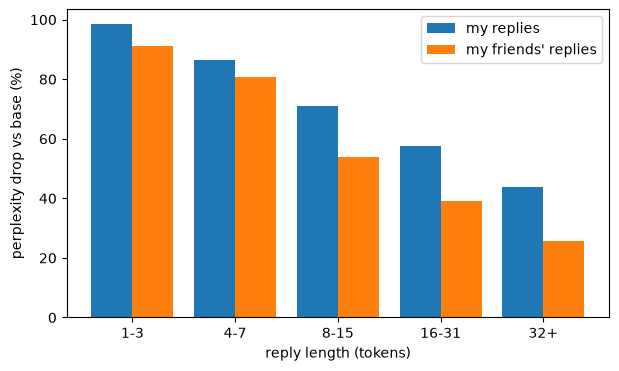

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(rows))
ax.bar(x - 0.2, [r[1] * 100 for r in rows], 0.4, label="my replies")
ax.bar(x + 0.2, [r[2] * 100 for r in rows], 0.4, label="my friends' replies")
ax.set_xticks(x, [r[0] for r in rows]); ax.set_xlabel("reply length (tokens)")
ax.set_ylabel("perplexity drop vs base (%)"); ax.legend()
plt.show()

## Conclusion

**Improvement over the base model (the decision 14 hypothesis): supported.** The drop in perplexity against the base model is huge on short replies and much smaller on long ones: for my replies 98.5% at 1-3 tokens and 86.4% at 4-7, against 57.6% at 16-31 and 43.9% at 32+ (my friends' follow the same shape). Most of what the adapter gains over the base model is on short messages, where it mostly has to learn to be brief and to close the message.

**Gap between me and my friends: length explains little.** My replies are only slightly shorter (median 13 against 14 tokens; mean 17.5 against 19.8). Reweighting my friends' replies to my length distribution lowers the signal from 19.8 to **16.9 points (95% CI 11.7 to 22.7)**: about 3 points were length, the rest stays. Inside each length bin my drop is larger than my friends' in every bin, and the gap is small on very short replies (5.6 to 7.4 points at 1-7 tokens) and large on longer ones (17.1 at 8-15 tokens, 18.5 at 16-31, 18.3 at 32+). The part that is specifically mine shows up where there is something to say, not in being brief.

Caveat: this controls for length only; the control group still differs in who is speaking, and their replies are scored under a system prompt that names me.